# Predicción de impago en tarjetas de credito

## EDA

Importamos paquetes

In [1]:
from random import random

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.feature_selection import f_classif, SelectKBest
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import plotly.graph_objects as go


In [2]:
# Para que las imagenes de plotly se puedan ver en github
import plotly.io as pio
pio.renderers.default = "png"

Leemos el dataset

In [3]:
df = pd.read_csv('application_record.csv')
df

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,6840104,M,N,Y,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0
438553,6840222,F,N,N,0,103500.0,Working,Secondary / secondary special,Single / not married,House / apartment,-15939,-3007,1,0,0,0,Laborers,1.0
438554,6841878,F,N,N,0,54000.0,Commercial associate,Higher education,Single / not married,With parents,-8169,-372,1,1,0,0,Sales staff,1.0
438555,6842765,F,N,Y,0,72000.0,Pensioner,Secondary / secondary special,Married,House / apartment,-21673,365243,1,0,0,0,NaN,2.0


Filas y columnas

In [4]:
df.shape

(438557, 18)

Información del dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL       

Significado de las variables:
- ID -> Identificador cliente
- CODE_GENDER -> Género del cliente (M = hombre, F = mujer)
- FLAG_OWN_CAR -> Indica si posee un vehículo (Y = sí, N = no)
- FLAG_OWN_REALTY -> Indica si posee propiedad inmobiliaria (Y = sí, N = no)
- CNT_CHILDREN -> Número de hijos
- AMT_INCOME_TOTAL -> Ingresos anuales
- NAME_INCOME_TYPE -> Tipo de ingreso (Working, Commercial associate, Pensioner, etc.)
- NAME_EDUCATION_TYPE -> Nivel educativo
- NAME_FAMILY_STATUS -> Estado civil
- NAME_HOUSING_TYPE -> Tipo de vivienda
- DAYS_BIRTH -> Edad en días (valores negativos)
- DAYS_EMPLOYED -> Días trabajados (negativo = empleado actualmente)
- FLAG_MOBIL -> Tiene teléfono móvil
- FLAG_WORK_PHONE -> Tiene teléfono de trabajo
- FLAG_PHONE -> Tiene teléfono fijo
- FLAG_EMAIL -> Tiene correo electrónico
- OCCUPATION_TYPE -> Tipo de ocupación laboral (Laborers, Accountants, Sales staff, etc.)
- CNT_FAM_MEMBERS -> Número total de miembros en la familia

Breve análisis descriptivo de los datos

In [6]:
df.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
count,4.385570e+05,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.0,438557.000000,438557.000000,438557.000000,438557.000000
mean,6.022176e+06,0.427390,1.875243e+05,-15997.904649,60563.675328,1.0,0.206133,0.287771,0.108207,2.194465
std,5.716370e+05,0.724882,1.100869e+05,4185.030007,138767.799647,0.0,0.404527,0.452724,0.310642,0.897207
min,5.008804e+06,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.0,0.000000,0.000000,0.000000,1.000000
25%,5.609375e+06,0.000000,1.215000e+05,-19483.000000,-3103.000000,1.0,0.000000,0.000000,0.000000,2.000000
50%,6.047745e+06,0.000000,1.607805e+05,-15630.000000,-1467.000000,1.0,0.000000,0.000000,0.000000,2.000000
75%,6.456971e+06,1.000000,2.250000e+05,-12514.000000,-371.000000,1.0,0.000000,1.000000,0.000000,3.000000
max,7.999952e+06,19.000000,6.750000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000


Vemos si hay valores nulos

In [7]:
df.isna().any()

ID                     False
CODE_GENDER            False
FLAG_OWN_CAR           False
FLAG_OWN_REALTY        False
CNT_CHILDREN           False
AMT_INCOME_TOTAL       False
NAME_INCOME_TYPE       False
NAME_EDUCATION_TYPE    False
NAME_FAMILY_STATUS     False
NAME_HOUSING_TYPE      False
DAYS_BIRTH             False
DAYS_EMPLOYED          False
FLAG_MOBIL             False
FLAG_WORK_PHONE        False
FLAG_PHONE             False
FLAG_EMAIL             False
OCCUPATION_TYPE         True
CNT_FAM_MEMBERS        False
dtype: bool

Vemos que hay valores nulos en OCCUPATION_TYPE, ahora contamos cuantos

In [8]:
df['OCCUPATION_TYPE'].isna().sum()

np.int64(134203)

Mostramos los nulos

In [9]:
df.loc[df['OCCUPATION_TYPE'].isna()]

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
7,5008812,F,N,Y,0,283500.0,Pensioner,Higher education,Separated,House / apartment,-22464,365243,1,0,0,0,NaN,1.0
8,5008813,F,N,Y,0,283500.0,Pensioner,Higher education,Separated,House / apartment,-22464,365243,1,0,0,0,NaN,1.0
9,5008814,F,N,Y,0,283500.0,Pensioner,Higher education,Separated,House / apartment,-22464,365243,1,0,0,0,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438549,6840098,F,N,Y,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0
438550,6840100,F,N,Y,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0
438551,6840102,F,N,Y,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0
438552,6840104,M,N,Y,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0


Como se trata de una variable categórica no podemos llenar los nulos con la media o la mediana y tampoco siguen un patrón por tanto los eliminamos

In [10]:
df = df.dropna()

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 304354 entries, 2 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   304354 non-null  int64  
 1   CODE_GENDER          304354 non-null  object 
 2   FLAG_OWN_CAR         304354 non-null  object 
 3   FLAG_OWN_REALTY      304354 non-null  object 
 4   CNT_CHILDREN         304354 non-null  int64  
 5   AMT_INCOME_TOTAL     304354 non-null  float64
 6   NAME_INCOME_TYPE     304354 non-null  object 
 7   NAME_EDUCATION_TYPE  304354 non-null  object 
 8   NAME_FAMILY_STATUS   304354 non-null  object 
 9   NAME_HOUSING_TYPE    304354 non-null  object 
 10  DAYS_BIRTH           304354 non-null  int64  
 11  DAYS_EMPLOYED        304354 non-null  int64  
 12  FLAG_MOBIL           304354 non-null  int64  
 13  FLAG_WORK_PHONE      304354 non-null  int64  
 14  FLAG_PHONE           304354 non-null  int64  
 15  FLAG_EMAIL           3

Como aún eliminando los nulos disponemos de más de 300000 filas vamos a cambiar las variables DAYS_BIRTH y DAYS_EMPLOYED para que estén en años para mejorar su interpretación y eliminar los valores atípicos

En DAYS_EMPLOYED el valor 365243 se utiliza para los jubilados, para poder hacer el cambio a años vamos a cambiar los días negativos por años como en days_birth y para el valor 365243 utilizaremos NaN.

In [12]:
# Creamos una nuevas columnas con los datos en años para ambas variables:

# DAYS_BIRTH
df['AGE_YEARS'] = (-df['DAYS_BIRTH'] / 365).round(0)

# DAYS_EMPLOYED
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
df['EMPLOYED_YEARS'] = (-df['DAYS_EMPLOYED'] / 365).round(0)

C:\Users\joaqu\AppData\Local\Temp\ipykernel_4396\195621680.py:4: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\joaqu\AppData\Local\Temp\ipykernel_4396\195621680.py:7: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\joaqu\AppData\Local\Temp\ipykernel_4396\195621680.py:8: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs

Comprobamos que la conversión de días a años es correcta

In [13]:
df[['DAYS_BIRTH', 'AGE_YEARS']].head()

,DAYS_BIRTH,AGE_YEARS
2,-21474,59.0
3,-19110,52.0
4,-19110,52.0
5,-19110,52.0
6,-19110,52.0


In [14]:
df[['DAYS_EMPLOYED', 'EMPLOYED_YEARS']].head()

,DAYS_EMPLOYED,EMPLOYED_YEARS
2,-1134,3.0
3,-3051,8.0
4,-3051,8.0
5,-3051,8.0
6,-3051,8.0


Como es correcta eliminamos las columnas en días ya que no nos aportan ningún valor

In [15]:
df.drop(columns=['DAYS_BIRTH', 'DAYS_EMPLOYED'], inplace=True)

C:\Users\joaqu\AppData\Local\Temp\ipykernel_4396\1386784800.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



Procedemos a eliminar los valores atípicos usando los cuartiles para 'AMT_INCOME_TOTAL', 'EMPLOYED_YEARS' y limitando el número de hijos y familiares

In [16]:
# Quitamos atípcios con regla de los cuartiles
for col in ['AMT_INCOME_TOTAL', 'EMPLOYED_YEARS']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    min_val = Q1 - 1.5 * IQR
    max_val = Q3 + 1.5 * IQR

    df[col] = df[col].clip(min_val, max_val)

# Limitamos el número de hijos y familiares
df['CNT_CHILDREN'] = df['CNT_CHILDREN'].clip(0, 5)
df['CNT_FAM_MEMBERS'] = df['CNT_FAM_MEMBERS'].clip(1, 7)

C:\Users\joaqu\AppData\Local\Temp\ipykernel_4396\3653829624.py:10: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\joaqu\AppData\Local\Temp\ipykernel_4396\3653829624.py:10: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

C:\Users\joaqu\AppData\Local\Temp\ipykernel_4396\3653829624.py:13: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/panda

Vemos como queda el dataset con las nuevas columnas, sin valores nulos y sin atípicos

In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 304354 entries, 2 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   304354 non-null  int64  
 1   CODE_GENDER          304354 non-null  object 
 2   FLAG_OWN_CAR         304354 non-null  object 
 3   FLAG_OWN_REALTY      304354 non-null  object 
 4   CNT_CHILDREN         304354 non-null  int64  
 5   AMT_INCOME_TOTAL     304354 non-null  float64
 6   NAME_INCOME_TYPE     304354 non-null  object 
 7   NAME_EDUCATION_TYPE  304354 non-null  object 
 8   NAME_FAMILY_STATUS   304354 non-null  object 
 9   NAME_HOUSING_TYPE    304354 non-null  object 
 10  FLAG_MOBIL           304354 non-null  int64  
 11  FLAG_WORK_PHONE      304354 non-null  int64  
 12  FLAG_PHONE           304354 non-null  int64  
 13  FLAG_EMAIL           304354 non-null  int64  
 14  OCCUPATION_TYPE      304354 non-null  object 
 15  CNT_FAM_MEMBERS      3

Nuevas variables:
- AGE_YEARS -> Edad (años)
- EMPLOYED_YEARS -> Años trabajados

In [18]:
df.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,AGE_YEARS,EMPLOYED_YEARS
count,3.043540e+05,304354.000000,304354.000000,304354.0,304354.000000,304354.000000,304354.000000,304354.000000,304354.000000,304354.000000
mean,6.022984e+06,0.510626,187324.965321,1.0,0.248152,0.285559,0.117534,2.297647,40.570592,6.864807
std,5.698275e+05,0.761818,78713.159359,0.0,0.431941,0.451681,0.322056,0.923126,9.560961,5.586681
min,5.008806e+06,0.000000,27000.000000,1.0,0.000000,0.000000,0.000000,1.000000,21.000000,0.000000
25%,5.617726e+06,0.000000,135000.000000,1.0,0.000000,0.000000,0.000000,2.000000,33.000000,3.000000
50%,6.047822e+06,0.000000,180000.000000,1.0,0.000000,0.000000,0.000000,2.000000,40.000000,5.000000
75%,6.449036e+06,1.000000,225000.000000,1.0,0.000000,1.000000,0.000000,3.000000,48.000000,10.000000
max,7.999952e+06,5.000000,360000.000000,1.0,1.000000,1.000000,1.000000,7.000000,68.000000,20.500000


Enriquecimiento o integración de datos:

Como podemos ver este dataset no tiene una variable target clara, nuestra variable target va a ser DEFAULT_EVER, es decir, si el cliente ha tenido algún atraso de más de 30 días en el pago

Importamos el dataset "credit_record"

In [19]:
df_credit = pd.read_csv(r'credit_record.csv')
df_credit.head(5)

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


No se puede añadir diréctamente el dataset porque tiene varias filas por cada ID de cliente, MONTHS_BALANCE indica los meses por tanto debemos crear la variable DEFAULT: vamos a considerar DEFAULT cuando la variable STATUS muestra un valor mayor a 1 lo que implica un retraso superior a 30 días en el pago.

In [20]:
# Creamos la variable DEFAULT
df_credit['DEFAULT_EVER'] = df_credit['STATUS'].isin(['1','2','3','4','5']).astype(int) # Si STATUS se encuentra en un número superior a 0 lo consideramos DEFAULT

In [21]:
# Tenemos DEFAULT para cada mes de cada cliente, ahora queremos que si DEFAULT ha sido 1 en algún mes se considere DEFAULT para el cliente
tabla_default = (df_credit.groupby('ID')['DEFAULT_EVER']
                                                    .max() # Si alguna vez DEFAULT ha sido 1 default cliente es 1
                                                    .reset_index() # Para que el índice sea ID
)

In [22]:
df_credit.shape

(1048575, 4)

In [23]:
df_credit.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1048575 entries, 0 to 1048574
Data columns (total 4 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   ID              1048575 non-null  int64 
 1   MONTHS_BALANCE  1048575 non-null  int64 
 2   STATUS          1048575 non-null  object
 3   DEFAULT_EVER    1048575 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 32.0+ MB


In [24]:
tabla_default = df_credit[['ID','DEFAULT_EVER']].groupby('ID').max()

Ahora que tenemos la variable creada las unimos al dataset

In [25]:
df = df.merge(tabla_default, on='ID', how='inner') # Utilizamos inner para solo introducir los datos que se correspondan con un usuario evitando nulos
df

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,AGE_YEARS,EMPLOYED_YEARS,DEFAULT_EVER
0,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,1,0,0,0,Security staff,2.0,59.0,3.0,0
1,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1,0,1,1,Sales staff,1.0,52.0,8.0,0
2,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1,0,1,1,Sales staff,1.0,52.0,8.0,0
3,5008810,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1,0,1,1,Sales staff,1.0,52.0,8.0,0
4,5008811,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,1,0,1,1,Sales staff,1.0,52.0,8.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25129,5149828,M,Y,Y,0,315000.0,Working,Secondary / secondary special,Married,House / apartment,1,0,0,0,Managers,2.0,48.0,7.0,1
25130,5149834,F,N,Y,0,157500.0,Commercial associate,Higher education,Married,House / apartment,1,0,1,1,Medicine staff,2.0,34.0,4.0,1
25131,5149838,F,N,Y,0,157500.0,Pensioner,Higher education,Married,House / apartment,1,0,1,1,Medicine staff,2.0,34.0,4.0,1
25132,5150049,F,N,Y,0,283500.0,Working,Secondary / secondary special,Married,House / apartment,1,0,0,0,Sales staff,2.0,49.0,2.0,1


In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25134 entries, 0 to 25133
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   25134 non-null  int64  
 1   CODE_GENDER          25134 non-null  object 
 2   FLAG_OWN_CAR         25134 non-null  object 
 3   FLAG_OWN_REALTY      25134 non-null  object 
 4   CNT_CHILDREN         25134 non-null  int64  
 5   AMT_INCOME_TOTAL     25134 non-null  float64
 6   NAME_INCOME_TYPE     25134 non-null  object 
 7   NAME_EDUCATION_TYPE  25134 non-null  object 
 8   NAME_FAMILY_STATUS   25134 non-null  object 
 9   NAME_HOUSING_TYPE    25134 non-null  object 
 10  FLAG_MOBIL           25134 non-null  int64  
 11  FLAG_WORK_PHONE      25134 non-null  int64  
 12  FLAG_PHONE           25134 non-null  int64  
 13  FLAG_EMAIL           25134 non-null  int64  
 14  OCCUPATION_TYPE      25134 non-null  object 
 15  CNT_FAM_MEMBERS      25134 non-null 

Una vez terminada la integración de datos y la limpieza, el Dataset tiene 19 columnas y 25134 filas (clientes)

### Análisis descriptivo de la variable target

In [27]:
count = df['DEFAULT_EVER'].value_counts()
count

DEFAULT_EVER
0    22045
1     3089
Name: count, dtype: int64

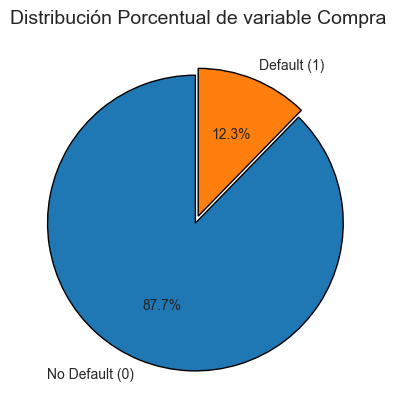

In [28]:
frecuencias = df["DEFAULT_EVER"].value_counts()
# 2. Definir etiquetas, colores y formato
etiquetas = ['No Default (0)', 'Default (1)']
explotar = [0.05, 0] # Separar un poco la porción mayoritaria (o la de interés)

plt.pie(
    frecuencias,
    labels=etiquetas,
    autopct='%1.1f%%', # Formato para mostrar el porcentaje
    startangle=90,     # Iniciar el primer segmento en la parte superior
    explode=explotar,
    wedgeprops={'edgecolor': 'black'} # Borde para mejor contraste
)

plt.title('Distribución Porcentual de variable Compra', fontsize=14)
plt.show()

La variable target nos indica que la mayoría de los clientes (87.7%) no entran en default, solo el 12,3% de los clientes entra en default en algún momento.

Estadísticos resumen

In [29]:
df.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,AGE_YEARS,EMPLOYED_YEARS,DEFAULT_EVER
count,2.513400e+04,25134.000000,25134.000000,25134.0,25134.000000,25134.000000,25134.000000,25134.000000,25134.000000,25134.000000,25134.000000
mean,5.078838e+06,0.510543,188026.457209,1.0,0.273812,0.292791,0.100660,2.292433,40.536166,6.910659,0.122901
std,4.194102e+04,0.765994,79077.120877,0.0,0.445923,0.455052,0.300885,0.931605,9.559474,5.507496,0.328330
min,5.008806e+06,0.000000,27000.000000,1.0,0.000000,0.000000,0.000000,1.000000,21.000000,0.000000,0.000000
25%,5.042228e+06,0.000000,135000.000000,1.0,0.000000,0.000000,0.000000,2.000000,33.000000,3.000000,0.000000
50%,5.079004e+06,0.000000,180000.000000,1.0,0.000000,0.000000,0.000000,2.000000,40.000000,5.000000,0.000000
75%,5.115604e+06,1.000000,225000.000000,1.0,1.000000,1.000000,0.000000,3.000000,48.000000,10.000000,0.000000
max,5.150487e+06,5.000000,360000.000000,1.0,1.000000,1.000000,1.000000,7.000000,67.000000,20.500000,1.000000


### Análisis descriptivo univariante de las características
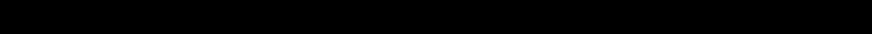

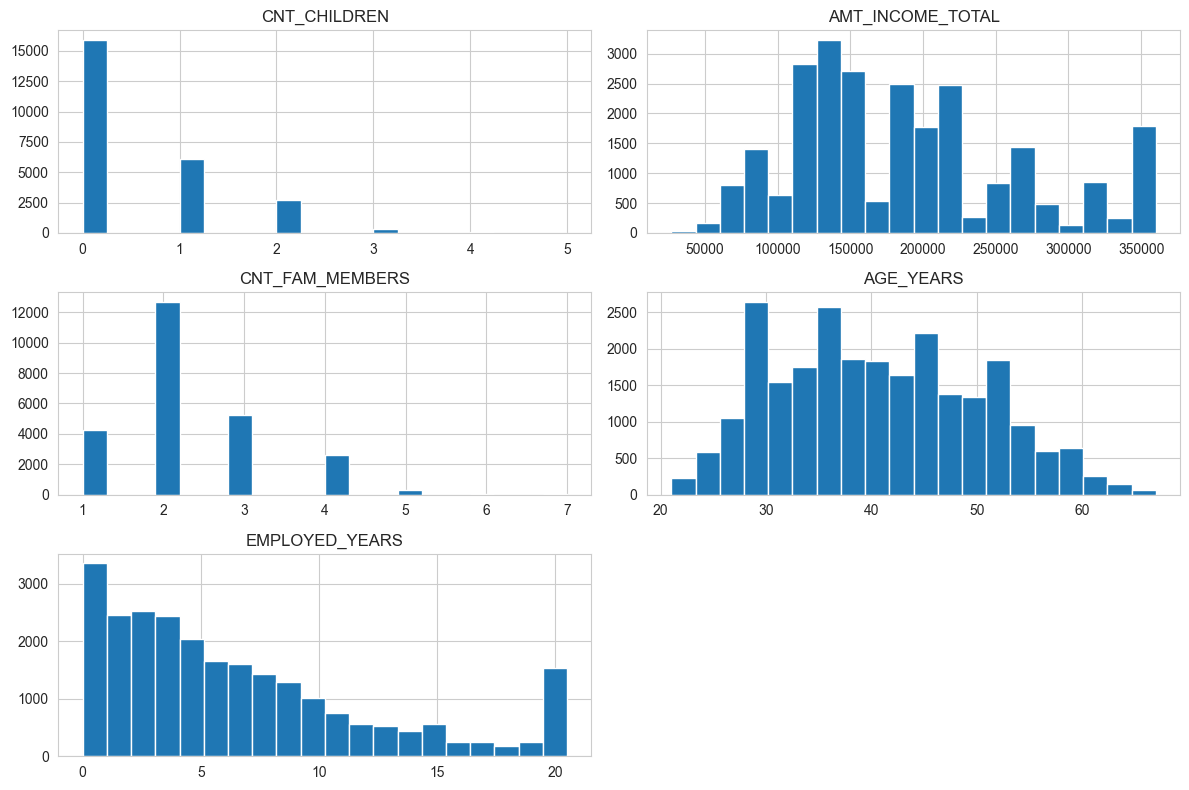

In [30]:
numerical_columns = ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'AGE_YEARS', 'EMPLOYED_YEARS']
df[numerical_columns].hist(bins=20, figsize=(12,8))
plt.tight_layout()
plt.show()

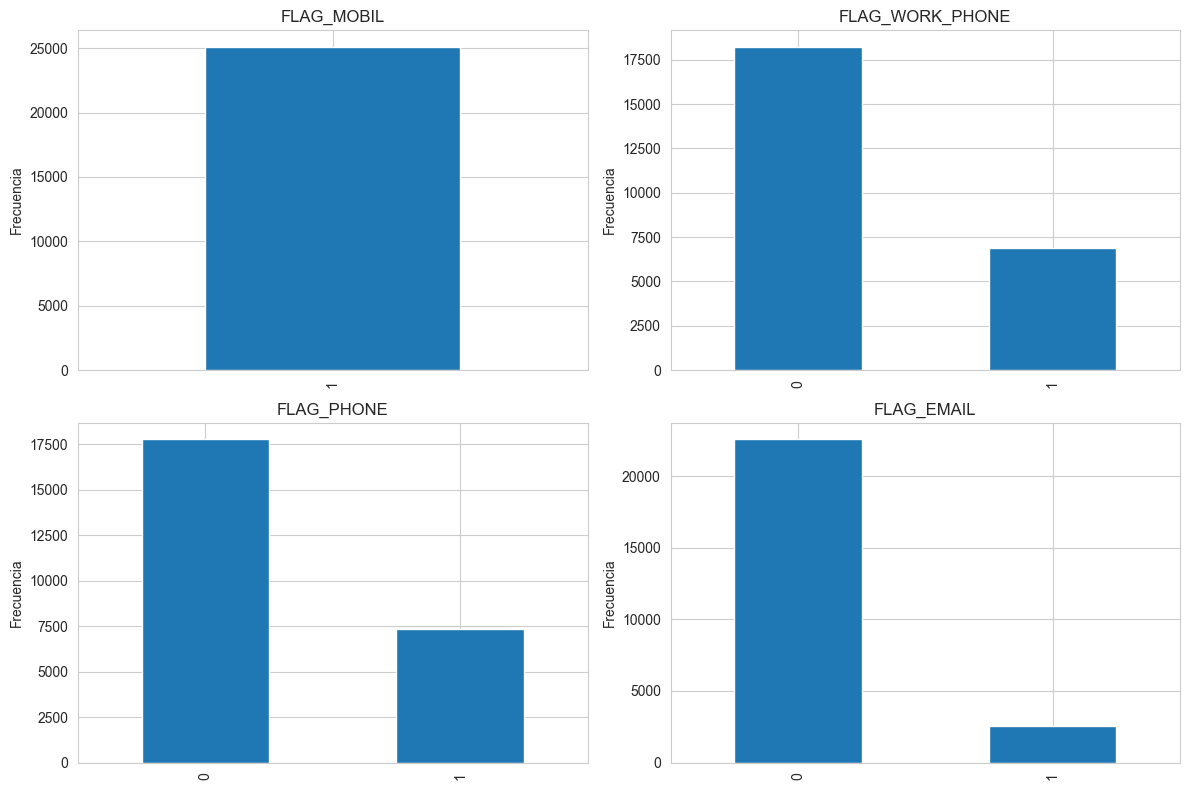

In [31]:
categorical_columns = ['FLAG_MOBIL','FLAG_WORK_PHONE','FLAG_PHONE','FLAG_EMAIL']

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, col in zip(axes, categorical_columns):
    df[col].value_counts().plot(kind='bar', ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()


En el análisis de las variables categóricas se observa que todos los clientes disponen de un movil, la cantidad de clientes que tienen teléfono fijo y teléfono de trabajo es similar y la cantidad de clientes con e-mail es la más baja.

### Matriz de correlaciones entre las varaibles

In [32]:
corr = df[['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'CNT_FAM_MEMBERS', 'AGE_YEARS', 'EMPLOYED_YEARS', 'FLAG_MOBIL','FLAG_WORK_PHONE','FLAG_PHONE','FLAG_EMAIL', 'DEFAULT_EVER']].corr()

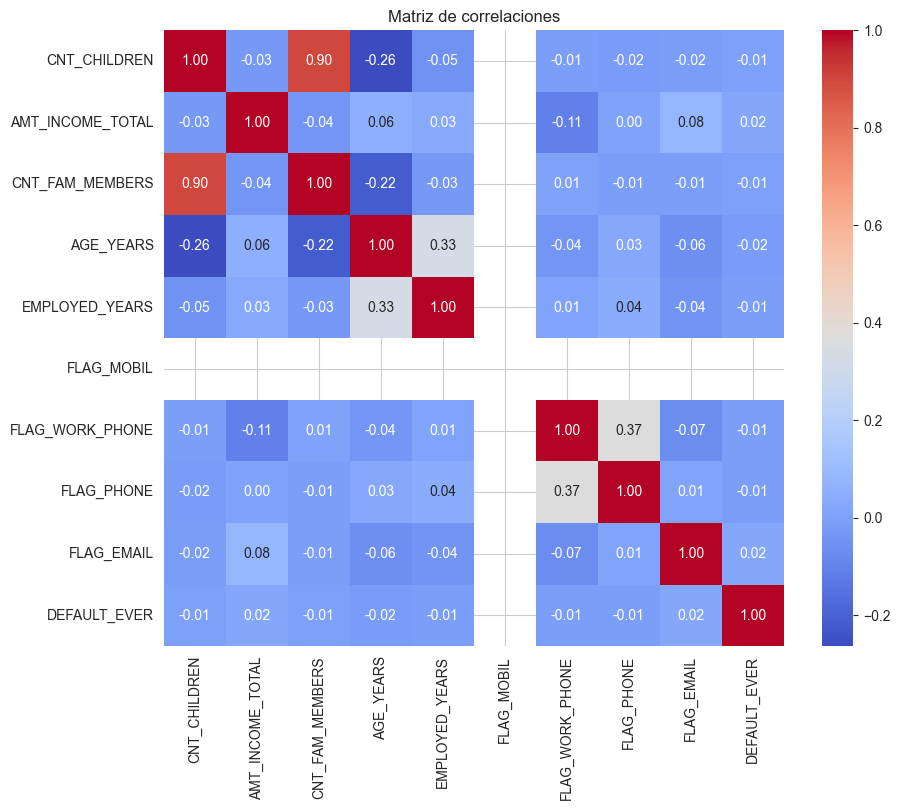

In [33]:
plt.figure(figsize=(10,8))
sns.heatmap(corr, cmap='coolwarm', annot=True,fmt='.2f')
plt.title('Matriz de correlaciones')
plt.show()

Como podemos observar la correlación de FLAG_MOBIL es nula, esto se debe a que todos sus valores son 1 por tanto su correlación es 0 o nula. Al tener todos los clientes movil esta variable no nos indica nada, tanto los que cometen default como los que no, disponen de un movil.

Analizando la matriz de correlaciones observamos que las relaciones entre las variables explicativas y la variable target son muy bajas y negativas en muchos casos. Esto nos indica que el incumplimiento de pago depende de múltiples factores y no puede explicarse mediante relaciones lineales.
Respecto a las relaciones con la variable target encontramos que la edad y los años trabajando tienen una correlación negativa, esto implica que las personas de mayor edad tienen menos probabilidad de cometer un impago lo que es coherente con la realidad, estas personas tienen una mayor estabilidad económica y laboral que los jóvenes.
La variable que muestra los ingresos anuales muestra una correlación muy baja positiva lo que nos indica que el comportamiento de pago no depende solo del salario sino que hay muchos otros factores a tener en cuenta.
En cuanto a las correlaciónes más altas que encontramos, la correlación número de hijos con número de miembros de la familia tiene la correlación más alta (0.9) lo que era de esperar porque a más hijos más miembros en la familia. Otra relación a destacar era otra predecible entre edad y años trabajados y por último encontramos la relación entre tener teléfono y tener teéfono de trabajo.
En conclusión, los resultados obtenidos tienen sentido ya que ninguna de las relaciones que observamos es incoherente pero las correlaciones observadas son muy bajas, esto puede deberse a que estas variables pueden estar correlacionadas pero no de forma lineal.

# **Trabajo final**

## Introducción, objetivos, hipótesis y utilidad práctica del análisis

* Este trabajo trata sobre un tema de clasificación en el ámbito del riesgo crediticio, se utiliza la información de los clientes para determinar la probabilidad de que estos incumplan algún pago.
* La variable target es DEFAULT_EVER una variable categórica que implica un retraso superior a 30 días en el pago.
* A priori la principal hipótesis es que los ingresos anuales sea la variable que más impacto tenga en la probabilidad de cometer un impago, aumentaando dicha probabilidad. Otra hipótesis es que un mayor nivel de estudios reduce la probabilidad de impago.
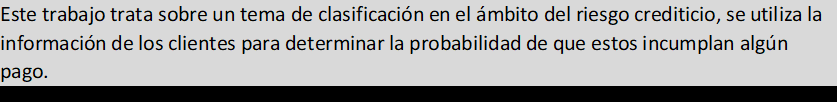
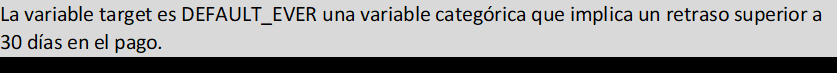

Nuevo dataset para predicción df_pred

In [34]:
df['NAME_HOUSING_TYPE_BOOL'] = np.where(df.NAME_HOUSING_TYPE.isin(['Rented apartment', 'Co-op apartment']), 1, 0) # Clasificamos a la gente que paga alquiler como 1 y los que no como 0
df['NAME_EDUCATION_TYPE_BOOL'] = np.where(df.NAME_EDUCATION_TYPE.isin(['Higher education', 'Academic degree']), 1, 0) # Dentro de educación nos quedamos solo con los que tienen educación superior como 1, el esto 0
df['NAME_FAMILY_STATUS_BOOL'] = np.where(df.NAME_FAMILY_STATUS.isin(['Married', 'Civil marriage']), 1, 0) # Dentro de la variable estado civil clasifico a casados y casados por lo civil como 1 y el resto como 0
df['OCCUPATION_TYPE_BOOL'] = np.where(df.OCCUPATION_TYPE.isin(['Accountants', 'High skill tech staff', 'HR staff', 'IT staff', 'Managers', 'Medicine staff', 'Realty agents']), 1, 0) # En occupation type separamos los trabajos de "más cualificación" como 1 y el resto como 0
df['NAME_INCOME_TYPE_BOOL'] = np.where(df.NAME_INCOME_TYPE == 'State servant', 1, 0) # Clasificamos a los funcionarios como 1 y al resto como 0
df = df.drop(columns=['ID','NAME_HOUSING_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS','OCCUPATION_TYPE','NAME_INCOME_TYPE'])

# Identificar categóricas
columnas_categoricas = columnas_categoricas = ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']

# One-hot encoding
df_pred = pd.get_dummies(df, columns=columnas_categoricas, drop_first=True, dtype=int)

# Como ya sabemos FLAG_MOBIL es 1 siempre, esto no nos aporta ninguna información y va a dar problemas en los modelos por lo que la eliminamos de df_pred
df_pred = df_pred.drop(columns=['FLAG_MOBIL'])

In [35]:
df_pred.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25134 entries, 0 to 25133
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CNT_CHILDREN              25134 non-null  int64  
 1   AMT_INCOME_TOTAL          25134 non-null  float64
 2   FLAG_WORK_PHONE           25134 non-null  int64  
 3   FLAG_PHONE                25134 non-null  int64  
 4   FLAG_EMAIL                25134 non-null  int64  
 5   CNT_FAM_MEMBERS           25134 non-null  float64
 6   AGE_YEARS                 25134 non-null  float64
 7   EMPLOYED_YEARS            25134 non-null  float64
 8   DEFAULT_EVER              25134 non-null  int64  
 9   NAME_HOUSING_TYPE_BOOL    25134 non-null  int64  
 10  NAME_EDUCATION_TYPE_BOOL  25134 non-null  int64  
 11  NAME_FAMILY_STATUS_BOOL   25134 non-null  int64  
 12  OCCUPATION_TYPE_BOOL      25134 non-null  int64  
 13  NAME_INCOME_TYPE_BOOL     25134 non-null  int64  
 14  CODE_G

## Análisis exploratorio-descriptivo del Dataset y preprocesamiento
a. El dataset utilizado es Credit Card Approval Prediction, fuente KAGGLE.
Credit Card Approval Prediction
El dataset cuenta con 2 fuentes de datos:
1. Application Record: contiene información general sobre los clientes.
2. Credit Record: contiene el historial crediticio mensual de los clientes.
Con esta segunda fuente se ha creado la varaible DEFAULT_EVER y para predecir se han convertido las variables categóricas varaibles dummies mediante One-hot encoding: NAME_HOUSING_TYPE_BOOL, NAME_HOUSING_TYPE_BOOL, NAME_EDUCATION_TYPE_BOOL, NAME_FAMILY_STATUS_BOOL, OCCUPATION_TYPE_BOOL, NAME_INCOME_TYPE_BOOL, CODE_GENDER_M, FLAG_OWN_CAR_Y, FLAG_OWN_REALTY_Y


b. Análisis univariante de la variable TARGET (y)** Porcentaje de "1" y "0" si es clasificación, y media, desviación típica, etc y un histograma en el caso de regresión.

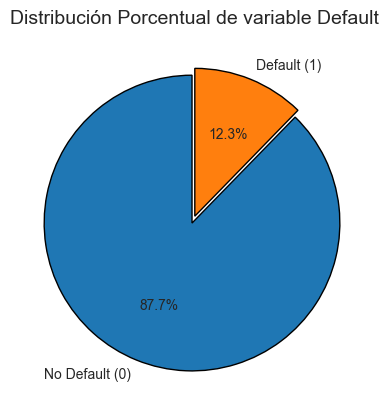

In [36]:
frecuencias = df_pred["DEFAULT_EVER"].value_counts()
# 2. Definir etiquetas, colores y formato
etiquetas = ['No Default (0)', 'Default (1)']
explotar = [0.05, 0] # Separar un poco la porción mayoritaria (o la de interés)

plt.pie(
    frecuencias,
    labels=etiquetas,
    autopct='%1.1f%%', # Formato para mostrar el porcentaje
    startangle=90,     # Iniciar el primer segmento en la parte superior
    explode=explotar,
    wedgeprops={'edgecolor': 'black'} # Borde para mejor contraste
)

plt.title('Distribución Porcentual de variable Default', fontsize=14)
plt.show()

In [37]:
df_pred['DEFAULT_EVER'].describe()

count    25134.000000
mean         0.122901
std          0.328330
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: DEFAULT_EVER, dtype: float64

Media 0.12 y desviación típica 0.33

c.	Tabla de variables X: nombre, tipo, qué mide, unidades y como crees que explica al target.
| Variable | Tipo | Qué mide | Unidades / escala | Cómo podría explicar el target (DEFAULT_EVER) |
|---|---|---|---|---|
| CNT_CHILDREN | Numérica discreta | Número de hijos a cargo | hijos (0,1,2,…) | Más hijos mayor probabilidad de default. |
| AMT_INCOME_TOTAL | Numérica continua | Ingreso total declarado | moneda | Más ingreso implica menor probabilidad de default. |
| FLAG_WORK_PHONE | Dummy (0/1) | Tiene teléfono del trabajo | 0/1 | Tener teléfono de trabajo implica una mayor responsabilidad por tanto un mejor cargo y menor probabilidad de default. |
| FLAG_PHONE | Dummy (0/1) | Tiene teléfono fijo/otro teléfono | 0/1 | No tener un teléfono se puede asociar con un aumento de la probabilidad de default. |
| FLAG_EMAIL | Dummy (0/1) | Tiene email registrado | 0/1 | Mayor contactabilidad puede implicar un descenso de la probabilidad de default. |
| CNT_FAM_MEMBERS | Numérica discreta | Miembros de la familia / miembros de familia | personas | Más miembros, más gastos mayor probabilidad de default. |
| AGE_YEARS | Numérica continua | Edad del solicitante | años | Más edad suele asociar estabilidad y experiencia laboral, por tanto una edad alta implica un descenso de la probabilidad de dafault. |
| EMPLOYED_YEARS | Numérica continua | Antigüedad laboral / años empleado | años | Más antigüedad, más estabilidad laboral y menor probabilidad de default. |
| DEFAULT_EVER | Dummy (0/1) | Target: ha incurrido en impago alguna vez | 0/1 | Variable objetivo. |
| NAME_HOUSING_TYPE_BOOL | Dummy (0/1) | Tipo de vivienda | 0/1 | Alguien alquilado puede tener un mayor riesgo de default. |
| NAME_EDUCATION_TYPE_BOOL | Dummy (0/1) | Nivel educativo | 0/1 | Mayor educación suele tener correlación con más ingresos y por tanto menos probabilidad de default. |
| NAME_FAMILY_STATUS_BOOL | Dummy (0/1) | Estado civil/familiar | 0/1 | Algunos estados como casado pueden asociarse con más estabilidad y por tanto menor riesgo de default. |
| OCCUPATION_TYPE_BOOL | Dummy (0/1) | Ocupación | 0/1 | Ocupaciones menos estables mayor riesgo de default. |
| NAME_INCOME_TYPE_BOOL | Dummy (0/1) | Tipo de ingreso | 0/1 | Ingresos irregulares o no seguros como autonomos pueden asociarse a um mayor riesgo de default. |
| CODE_GENDER_M | Dummy (0/1) | Género | 0/1 | Se podrá ver si el género es una variable que afecte al riesgo de default. |
| FLAG_OWN_CAR_Y | Dummy (0/1) | Tiene coche en propiedad | 0/1 | Si el hecho de tener un vehículo (patrimonio) influye en la probabilidad de default. |
| FLAG_OWN_REALTY_Y | Dummy (0/1) | Tiene vivienda/propiedad inmobiliaria | 0/1| Un mayor patrimonio implica más estabilidad y por tanto menos riesgo de default. |


d.	**Breve** análisis descriptivo DE LAS CARACTERÍSTICAS (x).

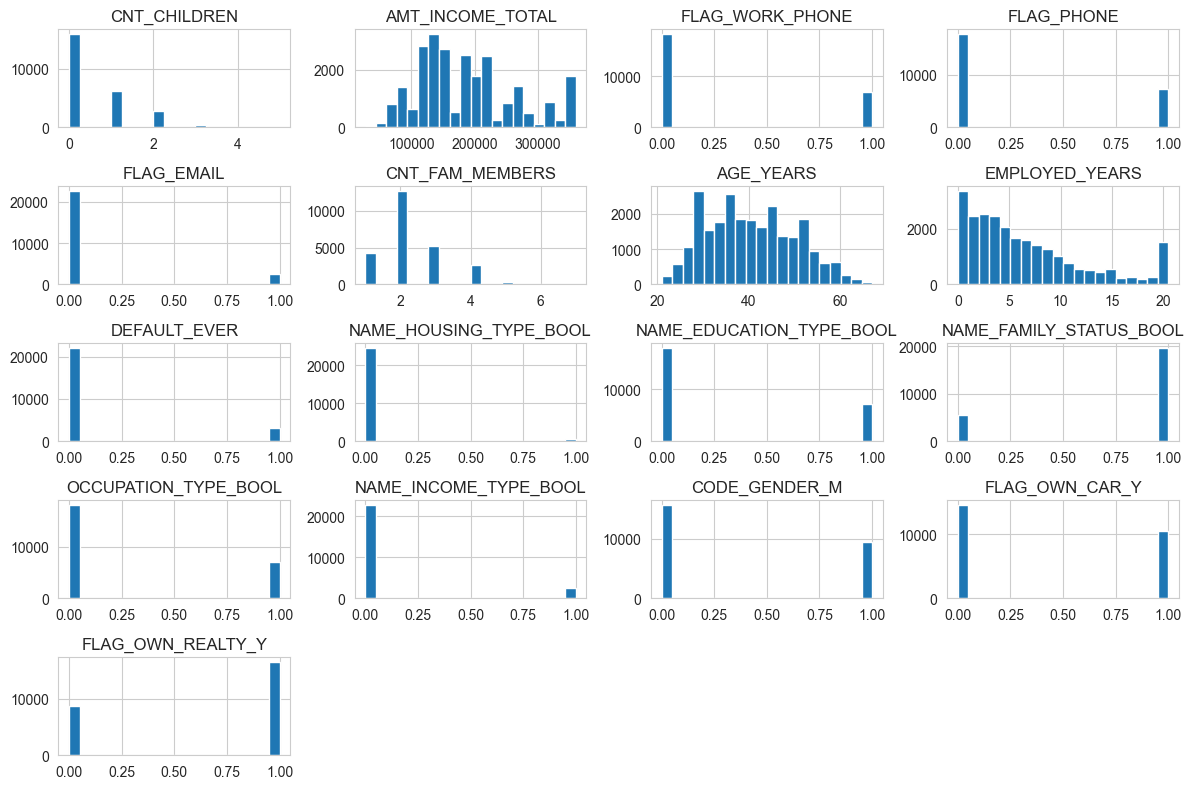

In [38]:
df_pred.hist(bins=20, figsize=(12,8))
plt.tight_layout()
plt.show()

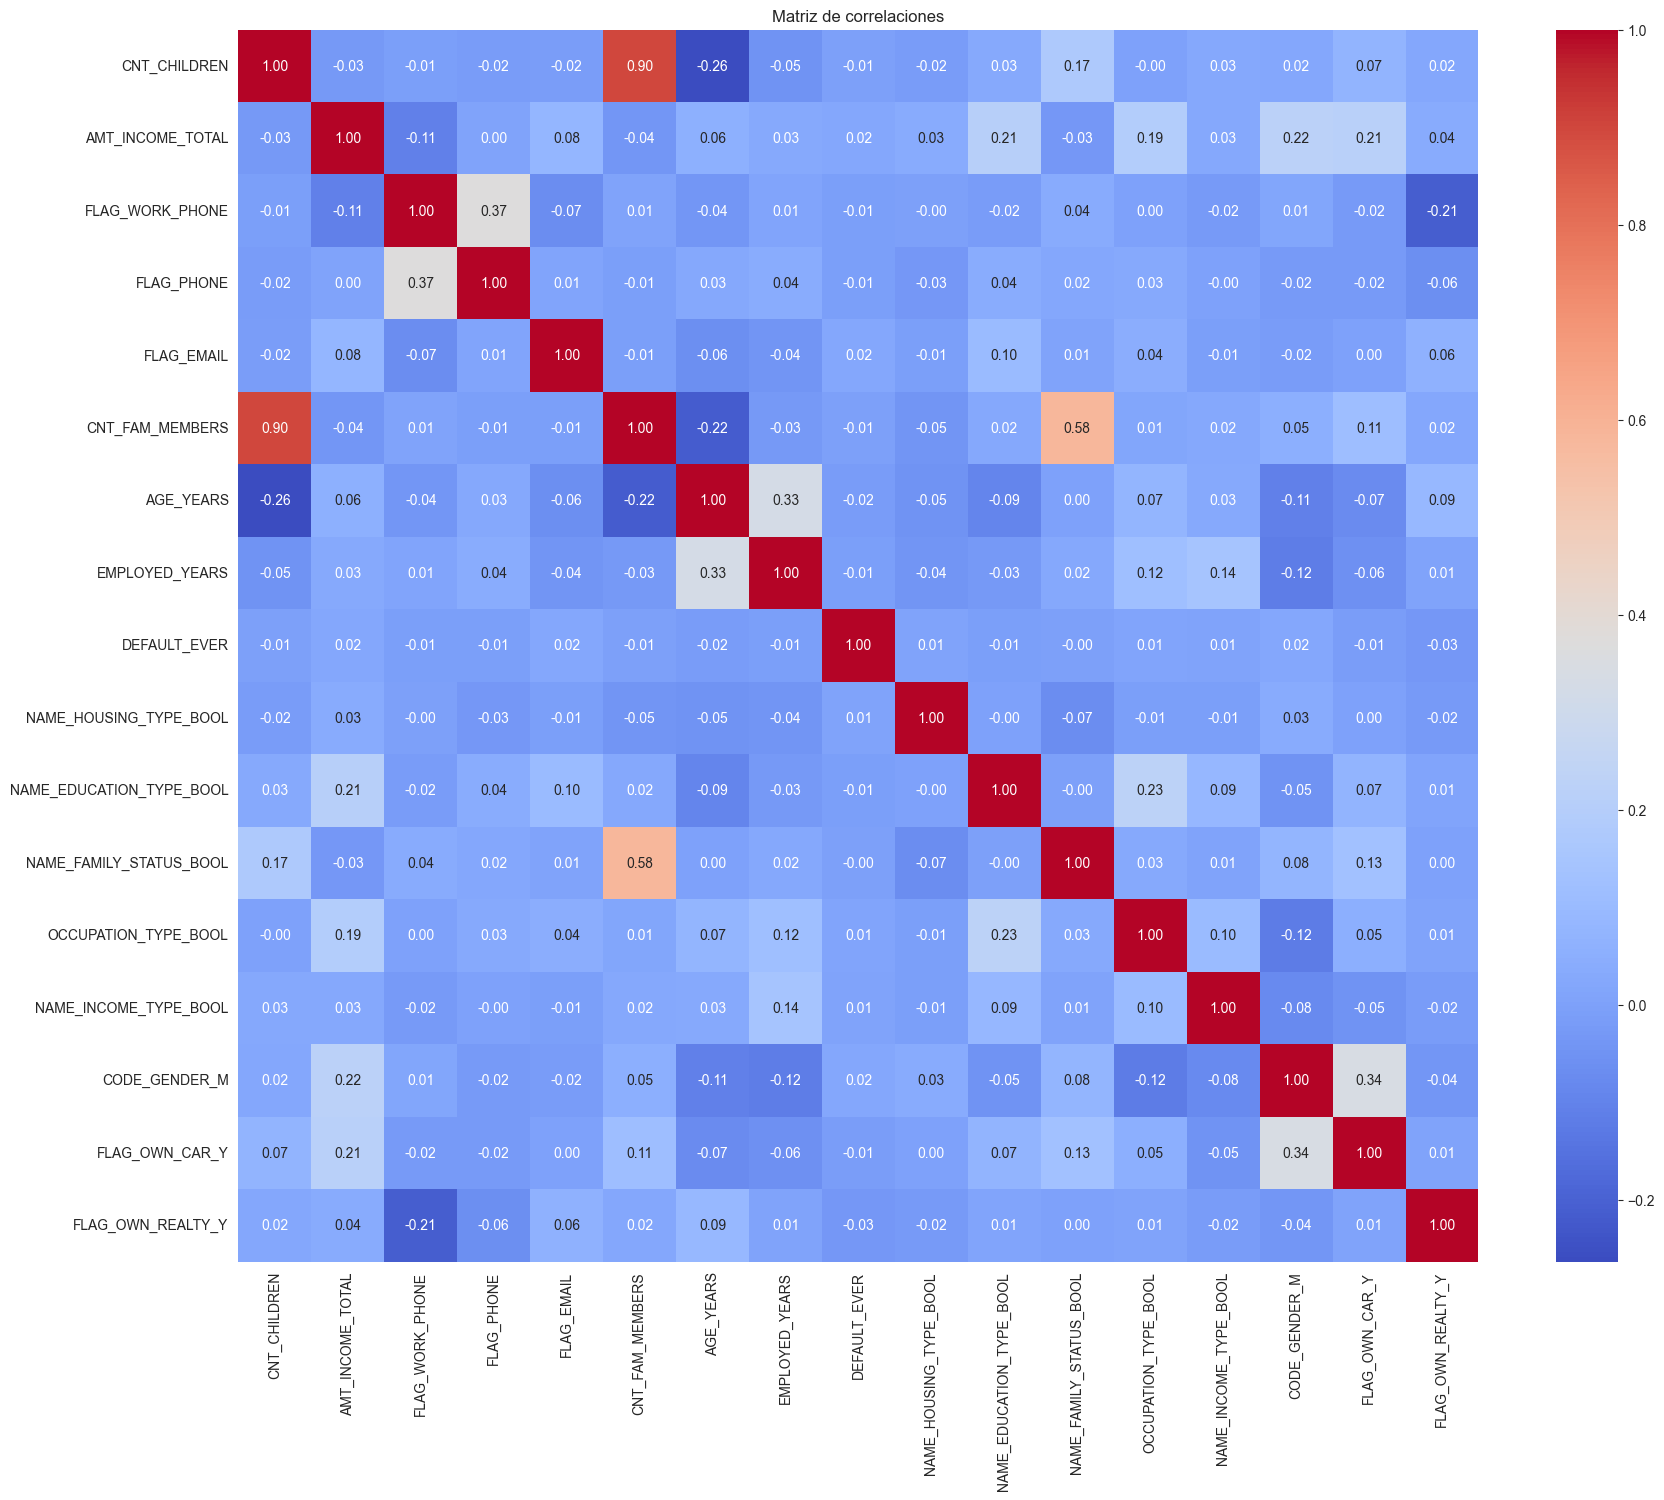

In [39]:
corr = df_pred.corr()

plt.figure(figsize=(20,16))
sns.heatmap(corr, cmap='coolwarm', annot=True,fmt='.2f')
plt.title('Matriz de correlaciones')
plt.show()

e.	Tratamiento de valores perdidos (NAs) y procedimiento de imputación si lo hubiera, tratamiento de outliers, codificación de variables cualitativas.

No hay valores perdidos ni outliers ya que han sido tratados en la propuesta en el dataset df y por tanto df_pred se ha creado con los datos tratados.

## Modelo Explicativo

Dado que la variable dependiente DEFAULT_EVER es categórica dicotómica he optado por un modelo de regresión logística (logit). Regresión Logística (Logit) Toma todas tus variables les asigna un peso y las suma.
-	Calcula una probabilidad entre 0 y 1
-	Si la suma de puntos supera el umbral clasifica como impago o no impago

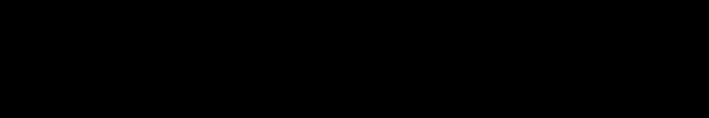

In [40]:
import statsmodels.formula.api as smf

In [41]:
modelo=smf.logit('DEFAULT_EVER ~ CNT_CHILDREN + AMT_INCOME_TOTAL + FLAG_WORK_PHONE + FLAG_PHONE + FLAG_EMAIL + CNT_FAM_MEMBERS + AGE_YEARS + EMPLOYED_YEARS + NAME_HOUSING_TYPE_BOOL + NAME_EDUCATION_TYPE_BOOL + NAME_FAMILY_STATUS_BOOL + OCCUPATION_TYPE_BOOL + NAME_INCOME_TYPE_BOOL + CODE_GENDER_M + FLAG_OWN_CAR_Y + FLAG_OWN_REALTY_Y', data=df_pred).fit()
print(modelo.summary())

Optimization terminated successfully.
         Current function value: 0.370683
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:           DEFAULT_EVER   No. Observations:                25134
Model:                          Logit   Df Residuals:                    25117
Method:                           MLE   Df Model:                           16
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                0.005321
Time:                        21:30:35   Log-Likelihood:                -9316.7
converged:                       True   LL-Null:                       -9366.6
Covariance Type:            nonrobust   LLR p-value:                 3.983e-14
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
Intercept                   -3.0805      0.442     -6.974      0.000      -3.946

Variables significativas (p-value < 0.05): CNT_CHILDREN, FLAG_EMAIL, CNT_FAM_MEMBERS,AGE_YEARS,NAME_EDUCATION_TYPE_BOOL, NAME_FAMILY_STATUS_BOOL, OCCUPATION_TYPE_BOOL, CODE_GENDER_M, FLAG_OWN_CAR_Y, FLAG_OWN_REALTY_Y
- CNT_CHILDREN: Coeficiente negativo por lo que, a más hijos se reduce la probabilidad de default
- AMT_INCOME_TOTAL: Unos ingresos anuales más altos aumentan ligeramente el riesgo de default. Esto puede estar explicado de forma similar a lo que ocurre en OCCUPATION_TYPE, es decir, perfiles con más dinero tienen un mayor acceso a créditos y apalancamiento, por tanto, una mayor probabilidad de cometer algún impago
- FLAG_EMAIL: Tener e-mail aumenta las probabilidades de default. Esto no se explica por ninguna correlación, ya que, en la matriz e-mail no tiene correlación con ninguna variable, esto puede deberse a que tener un e-mail impica un perfil más tecnológico y por tanto con accceso a créditos rápidos online o tarjetas de crédito online donde las regulaciones son menos exigentes y por tanto una mayor tasa de impago
- CNT_FAM_MEMBERS: Ser más miembros en la familia implica un aumento de la probabilidad de default, lo que se contradice con el número de hijos, puede ser por tener personas dependientes como los abuelos en casa
- AGE_YEARS: Una mayor edad reduce la probabilidad de default
- NAME_EDUCATION_TYPE_BOOL: Una educación superior disminuye la probabilidad de default
- NAME_FAMILY_STATUS_BOOL: El estar casado disminuye significativamente la probabilidad de default
- OCCUPATION_TYPE_BOOL: El tener una ocupación de "más cualificación" aumenta la probabilidad de default. Esto podría explicarse por su correlacion con EDUCATION_TYPE pero podemos descartar esto porque si eliminamos EDUCATION del logit nos sigue saliendo un coeficiente positivo de 0.1011. Una causa puede ser que estas personas con puestos más altos disponen de un mayor crédito y en ocasiones de apalancamientos, como DEFAULT_EVER mide si se ha cometido impago alguna vez, tiene sentido que estas personas con mayor acceso a crédito hayan cometido algún impago alguna vez
- CODE_GENDER_M: Ser hombre aumenta la probabilidad de default
- FLAG_OWN_CAR_Y: Tener un coche disminuye la probabilidad de default
- FLAG_OWN_REALTY_Y: Tener propiedades disminuye la probabilidad de default

El resto de variables no son significativas por lo que no nos aportan ninguna información.

## Flujo de la Metodología de Machine Learning

## Algoritmos predictivos

Código Evaluación Modelo

In [42]:
def _confusion_matrix(y_test, y_pred):

    # compute confusion matrix
    conf_matrix = confusion_matrix(y_test, y_pred)

    # prepare a table
    conf_matrix_df = pd.DataFrame(
        conf_matrix,
        index=['Actual Negatives', 'Actual Positives'],
        columns=['Pred. Negatives', 'Pred. Positives'])

    print(f'{conf_matrix_df}\n---------')


def _classification_metrics(y_test, y_pred, y_pred_scores):

    # compute some metrics
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_scores)

    # prepare full report
    report = classification_report(y_test, y_pred)

    print(f'{report}---------')
    print(f'F1: {f1:.3f} AUC: {auc:.3f}')


def _plot_auc(y_test, y_pred_scores):

    # Area Under the Curve
    fpr, tpr, thresholds = roc_curve(y_test,  y_pred_scores)
    auc = roc_auc_score(y_test, y_pred_scores)

    # prepare a DataFrame for plotting
    roc_df = pd.DataFrame({
        'FPR': fpr,
        'TPR': tpr,
        'Threshold': thresholds
    })

    # plot ROC Curve with hover text
    fig = go.Figure()
    fig.add_trace(go.Scatter(
        x=roc_df['FPR'],
        y=roc_df['TPR'],
        mode='lines+markers',
        hovertemplate=(
            'False Positive Rate (FPR): %{x:.3f}<br>' +
            'True Positive Rate (TPR): %{y:.3f}<br>' +
            'Threshold: %{customdata:.3f}<extra></extra>'
        ),
        customdata=roc_df['Threshold'],
        name=f'ROC Curve (AUC = {auc:.3f})'
    ))

    # add diagonal line (random classifier)
    fig.add_trace(go.Scatter(
        x=[0, 1],
        y=[0, 1],
        mode='lines',
        line=dict(dash='dash'),
        name='Random Classifier'
    ))

    # update layout
    fig.update_layout(
        title='ROC Curve',
        xaxis_title='False Positive Rate (FPR)',
        yaxis_title='True Positive Rate (TPR)',
        template='plotly_white',
        hovermode='closest',
        width=700, height=500
    )

    # show plot
    fig.show()


def evaluate_model(model, X_test, y_test, threshold=0.5):
    """ This function performs multiple evaluations on the given classifier """

    # Calculate predictions and probabilities

    y_pred_scores = model.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_scores >= threshold).astype(int)

    _confusion_matrix(y_test, y_pred)

    _classification_metrics(y_test, y_pred, y_pred_scores)

    _plot_auc(y_test, y_pred_scores)

### 1. Logit predictivo

In [43]:
# Separamos X e Y
X=df_pred.drop('DEFAULT_EVER', axis=1)
y=df_pred['DEFAULT_EVER']

# Partición aleatoria Train/Test 70/30
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test=train_test_split(X,y, test_size=0.3, random_state=42)

Logit igualando los pesos de las clases

a. El modelo utilizado es una regresión logística, un algoritmo de aprendizaje supervisado que se utiliza en problemas de clasificación binaria (nuestro caso).

La regresión logística modela la probabilidad de pertenencia a una clase utilizando una función logística (sigmoide), que transforma una combinación lineal de las variables explicativas en un valor comprendido entre 0 y 1. La predicción final se obtiene asignando la clase positiva cuando dicha probabilidad supera un determinado umbral.

b. El modelo se ha entrenado utilizando un Pipeline que consta de las siguientes etapas:

1. StandardScaler
Se emplea para estandarizar las variables, garantizando que todas tengan media cero y desviación típica uno.

2. SelectKBest
Selecciona las 9 variables con mayor relación estadística con la variable objetivo.

3. LogisticRegression
El hiperparámetro class_weight='balanced' se utiliza para compensar el desbalanceo de la varaible objetivo.

c. La regresión logística es un modelo interpretable por lo que no es necesario aplicar SHAP.

--- Pipeline(steps=[('scaler', StandardScaler()), ('select', SelectKBest(k=9)),
                ('logit', LogisticRegression(class_weight='balanced'))]) ---------------------------------------
                  Pred. Negatives  Pred. Positives
Actual Negatives             8472             6957
Actual Positives             1043             1121
---------
              precision    recall  f1-score   support

           0       0.89      0.55      0.68     15429
           1       0.14      0.52      0.22      2164

    accuracy                           0.55     17593
   macro avg       0.51      0.53      0.45     17593
weighted avg       0.80      0.55      0.62     17593
---------
F1: 0.219 AUC: 0.549


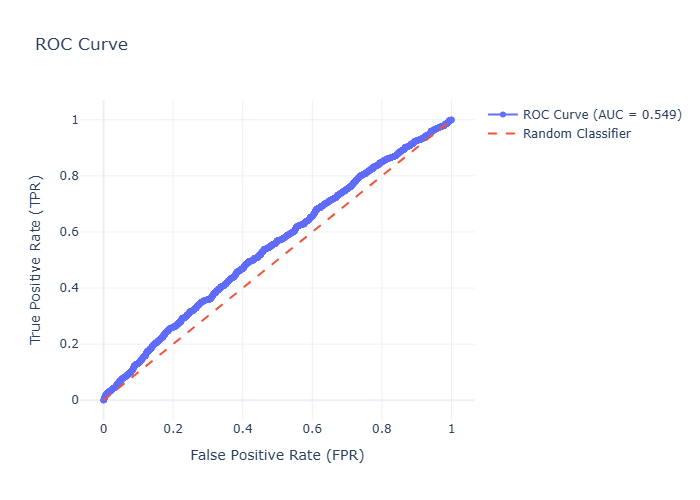

In [44]:
logit_1 = Pipeline([
    ('scaler', StandardScaler()),
    ('select', SelectKBest(k=9, score_func=f_classif)),
    ('logit', LogisticRegression(class_weight='balanced'))
])

logit_1.fit(X_train, y_train)
print(f'--- {logit_1} ---------------------------------------')
evaluate_model(logit_1, X_train, y_train)

El modelo predice igual en train y test por lo que ni sobre-ajusta ni infra-ajusta

                  Pred. Negatives  Pred. Positives
Actual Negatives             3745             2871
Actual Positives              462              463
---------
              precision    recall  f1-score   support

           0       0.89      0.57      0.69      6616
           1       0.14      0.50      0.22       925

    accuracy                           0.56      7541
   macro avg       0.51      0.53      0.45      7541
weighted avg       0.80      0.56      0.63      7541
---------
F1: 0.217 AUC: 0.537


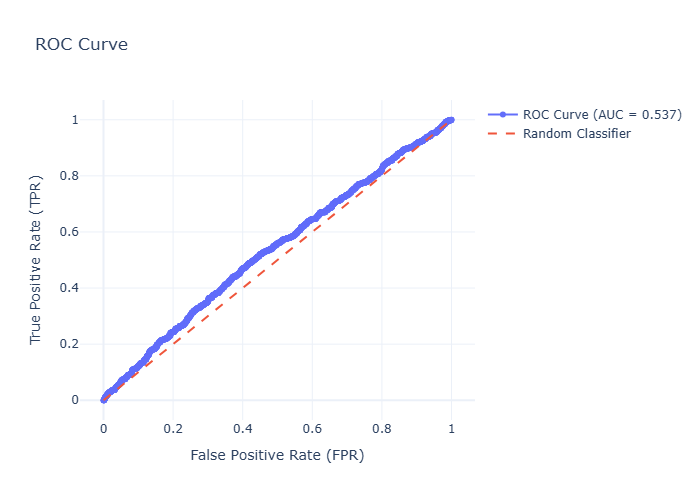

In [45]:
evaluate_model(logit_1, X_test, y_test)

- True Negatives(TN) = 3745 | Clientes que hicieron No default y el modelo predijo No default
- False Negatives(FN) = 462 | Clientes que hicieron Default y el modelo predijo No default
- True Positives(TP) = 463 | Clientes que hicieron Default y el modelo predijo Default
- False Positives(FP) = 2871 | Clientes que hicieron No default y el modelo predijo Default
- **Precision**
De los clientes que el modelo clasificó como no default, el 89% realmente lo eran
De los clientes que el modelo clasificó como default, el 14% realmente lo eran
- **Recall**
- Especificidad: El modelo identifica el 57% de los clientes que realmente no hicieron default
- Sensibilidad: El modelo identifica el 50% de los clientes que realmente hicieron default
- **F1 Score**
No nos importa f1 score porque asume que un falso negativo y un falso positivo tienen el mismo coste y en este caso eso no es verdad.
- **Accuracy**
El 56% de las observaciones son correctamente clasificadas
- **AUC**
Un AUC de 0.53 nos indica que si el modelo coge un cliente que hará default y uno que no, el modelo asigna una probabilidad más alta de default al que realmente hace default el 53% de las veces

Este caso se trata de un modelo bastante equilibrado identifica el 57% de los que realmente no hicieron default y el 50% de los que hicieron default. Si el coste de un falso positivo es inferior al de un falso negativo, vamos a suponer que en este caso lo es, podemos optar por un modelo un poco más agresivo que aumente la sensibilidad.

Logit más agresivo

--- Pipeline(steps=[('scaler', StandardScaler()), ('select', SelectKBest(k=9)),
                ('logit', LogisticRegression(class_weight={0: 1, 1: 8}))]) ---------------------------------------
                  Pred. Negatives  Pred. Positives
Actual Negatives             4626            10803
Actual Positives              535             1629
---------
              precision    recall  f1-score   support

           0       0.90      0.30      0.45     15429
           1       0.13      0.75      0.22      2164

    accuracy                           0.36     17593
   macro avg       0.51      0.53      0.34     17593
weighted avg       0.80      0.36      0.42     17593
---------
F1: 0.223 AUC: 0.549


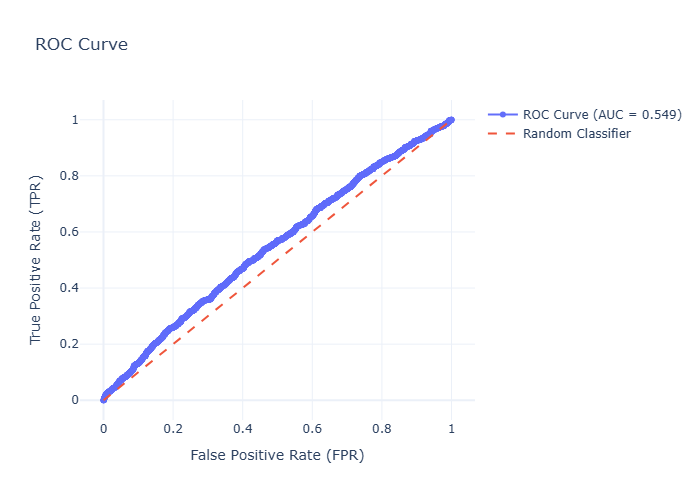

In [46]:
logit_2 = Pipeline([
    ('scaler', StandardScaler()),
    ('select', SelectKBest(k=9, score_func=f_classif)),
    ('logit', LogisticRegression(class_weight={0: 1, 1: 8})) # Ponemos un peso de 8 en DEFAULT
])

logit_2.fit(X_train, y_train)
print(f'--- {logit_2} ---------------------------------------')
evaluate_model(logit_2, X_train, y_train)

En este caso el modelo tampoco sobre-ajusta ni infra-ajusta

                  Pred. Negatives  Pred. Positives
Actual Negatives             2052             4564
Actual Positives              255              670
---------
              precision    recall  f1-score   support

           0       0.89      0.31      0.46      6616
           1       0.13      0.72      0.22       925

    accuracy                           0.36      7541
   macro avg       0.51      0.52      0.34      7541
weighted avg       0.80      0.36      0.43      7541
---------
F1: 0.218 AUC: 0.537


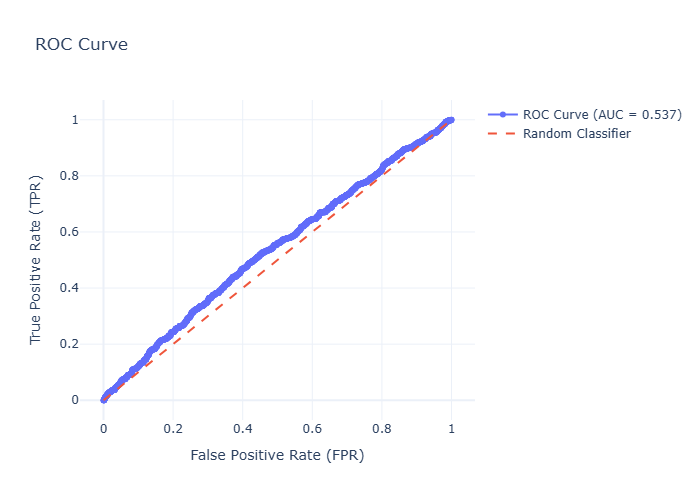

In [47]:
evaluate_model(logit_2, X_test, y_test)

- True Negatives(TN) = 2052
- False Negatives(FN) = 255
- True Positives(TP) = 670
- False Positives(FP) = 4564
- **Precisión**
De los clientes que el modelo clasificó como no default, el 89% lo eran
De lo clientes que el modelo clasificó como default, el 13% lo eran
- **Recall**
- Especificidad: El modelo identifica el 31% de los clientes que realmente no hicieron default
- Sensibilidad: El modelo identifica el 72% de los clientes que realmente hicieron default
- **Accuracy**
Se reduce a un 20% respecto al otro modelo, el 36% de las observaciones son correctamente clasificadas
- **AUC**
Un AUC de 0.53 nos indica que si el modelo coge un cliente que hará default y uno que no, el modelo asigna una probabilidad más alta de default al que realmente hace default el 53% de las veces

Este modelo se ha optimizado considerando que un falso negativo tiene un coste económico superior a un falso positivo. Este modelo identifica al 72% de los clientes que se van pero para eso hace predicciones muy agresivas lo que resulta en muchas falsas alarmas que bajan su precisión.

### 2. Random Forest

a. El modelo utilizado es un Random Forest, un algoritmo de aprendizaje supervisado basado en conjuntos de árboles de decisión (ensemble learning).

Random Forest crea múltiples árboles de decisión de forma independiente a partir de muestras aleatorias del conjunto de entrenamiento (lo que hace el hiperparámetro bootstrap). En cada nodo de cada árbol, el algoritmo considera únicamente un subconjunto aleatorio de variables esto se ha hecho para reducir la multicolinealidad.
La predicción final se obtiene mediante un voto mayoritario entre todos los árboles del conjunto.

b. Para el entrenamiento del modelo se ha utilizado un RandomForestClassifier con el hiperparámetro (class_weight='balanced'), con el objetivo de compensar el desbalanceo de la variable objetivo.
La optimización de parámetros se ha llevadoa cabo mediante random search:
- n_estimators: número de árboles
- max_depth: profundidad máxima de los árboles sireve para controlar la complejidad del modelo
- min_samples_split: número mínimo de observaciones necesarias para dividir un nodo, utilizado para reducir overfitting
- min_samples_leaf: número mínimo de observaciones necesarias para formar una hoja, utilizado para reducir overfitting
- max_features: indica cuantas variables se consideran en cada split del arbol, al reducir las variables los árboles son menos parecidos entre si lo que reduce el riesgo de overfitting
- max_samples: Controla qué proporción del conjunto de entrenamiento se utiliza para entrenar cada árbol (cuando bootstrap = true)
- bootstrap: indica si cada árbol del Random Forest se entrena usando una muestra aleatoria con reemplazo del conjunto de entrenamiento original

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters: {'n_estimators': 600, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_samples': 0.9, 'max_features': 'sqrt', 'max_depth': 12, 'bootstrap': True}
Best CV score: 0.7167215088294054
--- RandomForestClassifier(class_weight='balanced', max_depth=12, max_samples=0.9,
                       min_samples_leaf=5, min_samples_split=10,
                       n_estimators=600, random_state=42) ---------------------------------------
                  Pred. Negatives  Pred. Positives
Actual Negatives             7816             7613
Actual Positives               22             2142
---------
              precision    recall  f1-score   support

           0       1.00      0.51      0.67     15429
           1       0.22      0.99      0.36      2164

    accuracy                           0.57     17593
   macro avg       0.61      0.75      0.52     17593
weighted avg       0.90      0.57      0.63     17593
---

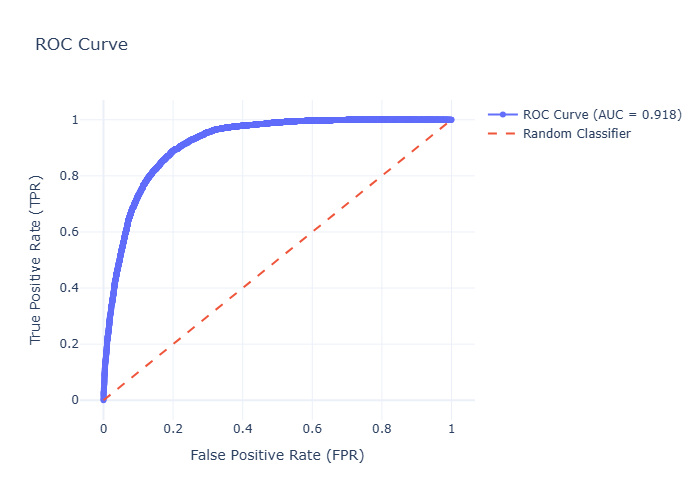

In [48]:
rf = RandomForestClassifier(class_weight='balanced', random_state=42) # Se pone class_weight 'balanced' porque aumenta el recall

param_dist = {
    'n_estimators': [300, 600, 900],
    'max_depth': [5, 8, 12],
    'min_samples_split': [10, 20,50, 100],
    'min_samples_leaf': [5, 10, 20, 50],
    'bootstrap': [True], # Crea muestras del dataset original reduciendo multicolinealidad
    'max_features': ['sqrt', 0.3, 0.5], # Max_features indica cuantas variables se consideran en cada split del arbol, al reducir las variables los árboles son menos parecidos entre si lo que reduce el overfitting
    'max_samples': [0.7, 0.9]

}
# Hacemos random search
# random hace las mismas pruebas que grid pero prueba muchos más valores de alfa y beta o de x e y en la matriz
random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=10,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), #n_splits = 5, el dataset se divide en 5 folds, en cada iteración de entrena con 4 folds y valida con 1  # shuffle=True hace que datos se mezclen aleatoriamente antes de dividirse en los 5 folds.
    scoring='roc_auc',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# perform the random search
random_search.fit(X_train, y_train)

# get the best model, parameters and score
best_model = random_search.best_estimator_
best_params = random_search.best_params_
best_score = random_search.best_score_

print("Best parameters:", best_params)
print("Best CV score:", best_score)

print(f'--- {best_model} ---------------------------------------')
evaluate_model(best_model, X_train, y_train, threshold=0.35)

                  Pred. Negatives  Pred. Positives
Actual Negatives             3053             3563
Actual Positives              193              732
---------
              precision    recall  f1-score   support

           0       0.94      0.46      0.62      6616
           1       0.17      0.79      0.28       925

    accuracy                           0.50      7541
   macro avg       0.56      0.63      0.45      7541
weighted avg       0.85      0.50      0.58      7541
---------
F1: 0.280 AUC: 0.724


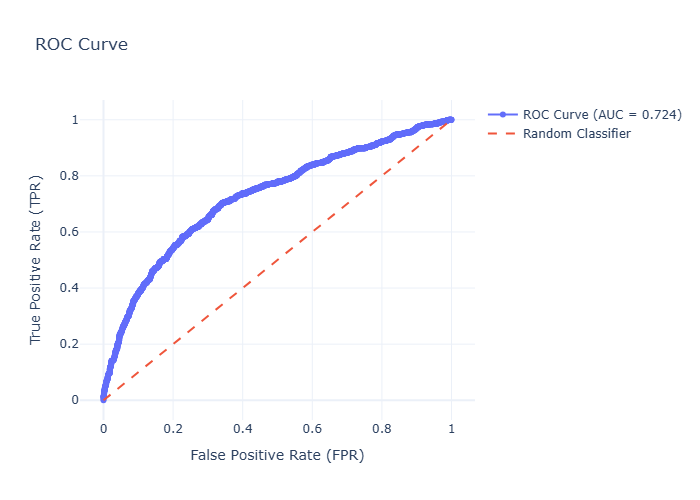

In [49]:
evaluate_model(best_model, X_test, y_test, threshold=0.35)

La diferencia que hay entre el AUC en train 0.918 y el AUC en test 0.72 nos indica overfitting, esta diferencia es la más baja que he logrado manteniendo el resto de valores en rangos aceptables.
- True Negatives(TN) = 3053
- False Negatives(FN) = 193
- True Positives(TP) = 732
- False Positives(FP) = 3563
- **Precisión** De los clientes que el modelo clasificó como default, el 17% lo eran
- **Recall**
- En train podemos ver que el modelo tiene un recall de 0.99 lo que nos indica que el modelo identifica el 99% de los clientes que realmente hacen default que es justo lo que buscamos.
- En test este valor baja a identificar el 79% de los clientes que realmente cometen default y el 46% de los que cometen no default
- **AUC**
Un AUC de 0.72 nos indica que si el modelo coge un cliente que hará default y uno que no, el modelo asigna una probabilidad más alta de default al que realmente hace default el 72% de las veces

Un alto valor de recall nos indica que es un modelo agresivo, es decir, logra identificar al 79% de los clientes que se van pero para lograr esto marca como posible default a muchos clientes que luego no cometen default lo que explica la precisión tan baja
Este modelo se ha optimizado considerando que un falso negativo tiene un coste económico superior a un falso positivo, es decir, preferimos falsos positvos que son fáciles de solucionar antes que falsos negativos que son muy costosos, el modelo está ajustado correctamente porque identifica al 79% de los clientes que cometen default pero al hacer una predicción tan agresiva, tan solo el 17% de estos realmente cometieron default.
El modelo presenta un claro overfitting a pesar de haberlo tratado de reducir, aun así, es el mejor de los modelos para este caso, tiene el AUC más alto de todos un 72% que en riego creditíceo es acceptable, además tiene un recall de 79% en dafault 1, identifica al 79% de los clientes que cometen default. Su precisión es de un 17% que a pesar de ser muy baja es la más alta de los modelos.

### 3. Red Neuronal

a. El modelo utilizado es una red neuronal multicapa (MLP, Multi-Layer Perceptron)
Un MLP está formado por una capa de entrada, una o varias capas ocultas con neuronas y una capa de salida. Cada neurona aplica una transformación lineal seguida de una función de activación (por ejemplo relu o tanh), permitiendo al modelo aprender relaciones no lineales. El entrenamiento se realiza mediante un algoritmo de optimización (en este caso adam) que ajusta los pesos para minimizar la función de pérdida.
b. El modelo se entrena mediante un Pipeline
- StandardScaler: Se aplica escalado (media 0, varianza 1)
- MLPClassifier que se configura con:
    1. max_iter=500: máximo de iteraciones/épocas
    2. early_stopping=True, n_iter_no_change=20 y validation_fraction=0.15: se usa un conjunto de validación interno (valid_fraction) (15% del train) para detener el entrenamiento si no mejora en 20 iteraciones (n_iter_no_change), para reducir el riesgo de overfitting
La optimización de hiperparámetros se realiza con Random Search:
- estimator: indica el modelo sobre el que se van a buscar lso hiperparámetros
- n_iter: cantidad de configuraciones que se evaluan del modelo
- cv: validación cruzada donde n_splits = 5, el dataset se divide en 5 folds, en cada iteración de entrena con 4 folds y valida con 1 y shuffle=True hace que datos se mezclen aleatoriamente antes de dividirse en los 5 folds.
- scoring: ponemos como métric objetivo recall que es la que buscamos maximizar
- n_jobs: hace que trabaje más la cpu reduciendo e tiempo de entrenamiento
- verbose: nivel de información que nos muestra el modelo
- random_state: siempre el mismo para que los datos aleatorios se repitan
- param distribution: la distribución de parámetros incluye:
    - hidden_layer_sizes: número de capas y neuronas
    - activation: función de activación relu
    - alpha: regularización L2 introducida para reducir ovverfitting
    - learning_rate_init: es la tasa de aprendizaje inicial que tamaño de los pesos del optimizador
    - batch_size: tamaño del batch

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'mlp__solver': 'adam', 'mlp__learning_rate_init': 0.01, 'mlp__hidden_layer_sizes': (32, 16), 'mlp__batch_size': 128, 'mlp__alpha': 0.01, 'mlp__activation': 'tanh'}
Best CV score: 0.024961508852963814
Threshold 0.5: Recall=0.031, Precision=0.537, FN=896
Threshold 0.4: Recall=0.057, Precision=0.371, FN=872
Threshold 0.3: Recall=0.107, Precision=0.287, FN=826
Threshold 0.25: Recall=0.169, Precision=0.249, FN=769
Threshold 0.2: Recall=0.278, Precision=0.226, FN=668
Threshold 0.15: Recall=0.415, Precision=0.188, FN=541
Threshold 0.1: Recall=0.626, Precision=0.158, FN=346
                  Pred. Negatives  Pred. Positives
Actual Negatives             8388             7041
Actual Positives              560             1604
---------
              precision    recall  f1-score   support

           0       0.94      0.54      0.69     15429
           1       0.19      0.74      0.30      2164

    accuracy        

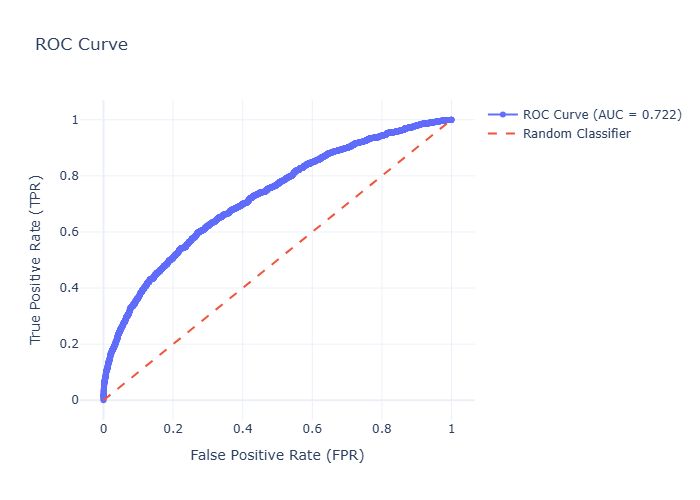

In [50]:
# 1. Creamos el pipeline

pipeline = Pipeline([
    ('scaler', StandardScaler()),  # Escalado obligatorio para redes neuronales
    ('mlp', MLPClassifier(
        max_iter=500,              # Máximo de épocas
        early_stopping=True,       # EARLY STOPPING activado
        n_iter_no_change=20,       # Parar si no mejora en 20 épocas
        validation_fraction=0.15,  # 15% de train para validación interna
        random_state=42
    ))
])


# 2. Parámetros para crear una red grande con L2 + Early stopping (ya lo tenemos) para evitar overfiting

# Arquitectura de la red, red grande con un alto número de capas y neuronas
# Usamos param distributions porque vamos a usar random search no grid search
param_distributions = {'mlp__hidden_layer_sizes': [(32,), (64,), (32,16), (64,32)],
                        'mlp__activation': ['relu', 'tanh'],  # Función de activación
                        'mlp__solver': ['adam'],  # Optimizador
                        'mlp__alpha': [0.01, 0.1], # L2 Regularización (alpha) para evitar overfitting
                        'mlp__learning_rate_init': [0.001, 0.01],  # Learning rate
                        'mlp__batch_size': [32, 64, 128]}  # Batch size


# 3. RANDOM SEARCH

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=30,                    # Número de combinaciones a probar
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), #n_splits = 5, el dataset se divide en 5 folds, en cada iteración de entrena con 4 folds y valida con 1  # shuffle=True hace que datos se mezclen aleatoriamente antes de dividirse en los 5 folds.
    scoring='recall',            # Buscamos aumentar recall en este caso
    n_jobs=-1,                    # Hace que trabajen todos los núcleos disponibles de la cpu
    verbose=2,                    # Muestra el progreso progreso
    random_state=42
)

# 4. ENTRENAR

random_search.fit(X_train, y_train)

# 5. Buscamos los mejores parámetros

best_score = random_search.best_score_
best_params = random_search.best_params_
print("Best parameters:", best_params)
print("Best CV score:", best_score)

# Obtener mejor modelo
best_model = random_search.best_estimator_

# 6. Buscamos el threshold que maximice recall, que es lo que buscamos en este caso

y_proba_test = best_model.predict_proba(X_test)[:, 1]  # Obtenemos probabilidades de la clase 1

# Probamos diferentes thresholds
for threshold in [0.5, 0.4, 0.3, 0.25, 0.2, 0.15, 0.1]:
    y_pred = (y_proba_test >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    print(f"Threshold {threshold}: Recall={tp/(tp+fn):.3f}, Precision={tp/(tp+fp):.3f}, FN={fn}")

# 7. Aplicamos el threshold óptimo para este modelo

y_proba_test = best_model.predict_proba(X_test)[:, 1]
y_pred_final = (y_proba_test >= 0.1).astype(int)

# 8. Evaluamos el modelo

evaluate_model(best_model, X_train, y_train, threshold=0.10)

                  Pred. Negatives  Pred. Positives
Actual Negatives             3520             3096
Actual Positives              346              579
---------
              precision    recall  f1-score   support

           0       0.91      0.53      0.67      6616
           1       0.16      0.63      0.25       925

    accuracy                           0.54      7541
   macro avg       0.53      0.58      0.46      7541
weighted avg       0.82      0.54      0.62      7541
---------
F1: 0.252 AUC: 0.621


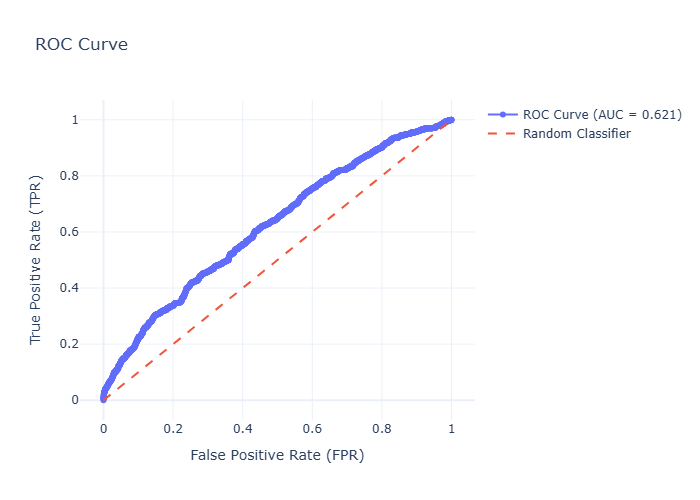

In [51]:
evaluate_model(best_model, X_test, y_test, threshold=0.10)

- True Negatives(TN) = 3520 | Clientes que hicieron No default y el modelo predijo No default
- False Negatives(FN) = 346 | Clientes que hicieron Default y el modelo predijo No default
- True Positives(TP) = 579 | Clientes que hicieron Default y el modelo predijo Default
- False Positives(FP) = 3096 | Clientes que hicieron No default y el modelo predijo Default
- **Precision**
De los clientes que el modelo clasificó como no default, el 91% realmente lo eran
De los clientes que el modelo clasificó como default, el 16% realmente lo eran
- **Recall**
- Especificidad: El modelo identifica el 53% de los clientes que realmente no hicieron default
- Sensibilidad: El modelo identifica el 63% de los clientes que realmente hicieron default
- **F1 Score**
No nos importa f1 score porque asume que un falso negativo y un falso positivo tienen el mismo coste y en este caso eso no es verdad.
- **Accuracy**
El 54% de las observaciones son correctamente clasificadas
- **AUC**
Un AUC de 0.62 nos indica que si el modelo coge un cliente que hará default y uno que no, el modelo asigna una probabilidad más alta de default al que realmente hace default el 62% de las veces

Para reducir el overfitting lo máximo posible se he optado por una red neuronal pequeña con regularización, se usa tanto L2 como EarlyStopping para evitar overfitting. Ha sido entrenada para ser un modelo agresivo que trata de minimizar los falsos negativos. Tras reducir su complejidad para evitar un alto overfitting vemos que no puede competir con los resultados de random forest por lo que la conclusión es que la red neuronal no es el modelo adecuado para este problema concreto de datos financieros muy desbalanceados. Esto no significa que la red neuronal no pueda ser eficaz con datos financieros, simplemente nos muestra que con un número de datos tan pequeño tiende a hacer overfitting y si reducimos mucho su complejidad para evitar esto predice peor que otros modelos, pero probablemente en dataset con más datos y mejor balanceados tenga mejores resultados.

## Conclusiones

| **Métrica**                  | **Logit**                                                                                                                                                                                                                                                                                                                                               | **Random Forest**                                                                                                                                                                                                                                                                                                       | **Red Neuronal**                                                                                                                                                                                                                                                                                        |
| ---------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **True Positives (TP)**      | 670                                                                                                                                                                                                                                                                                                                                                     | 732                                                                                                                                                                                                                                                                                                                     | 579                                                                                                                                                                                                                                                                                                     |
| **True Negatives (TN)**      | 2052                                                                                                                                                                                                                                                                                                                                                    | 3053                                                                                                                                                                                                                                                                                                                    | 3520                                                                                                                                                                                                                                                                                                    |
| **False Positives (FP)**     | 4564                                                                                                                                                                                                                                                                                                                                                    | 3563                                                                                                                                                                                                                                                                                                                    | 3096                                                                                                                                                                                                                                                                                                    |
| **False Negatives (FN)**     | 255                                                                                                                                                                                                                                                                                                                                                     | 193                                                                                                                                                                                                                                                                                                                     | 346                                                                                                                                                                                                                                                                                                     |
| **Precisión (default = 1)**  | 13%                                                                                                                                                                                                                                                                                                                                                     | 17%                                                                                                                                                                                                                                                                                                                     | 16%                                                                                                                                                                                                                                                                                                     |
| **Precisión (default = 0)**  | 89%                                                                                                                                                                                                                                                                                                                                                     | 86%                                                                                                                                                                                                                                                                                                                     | 92%                                                                                                                                                                                                                                                                                                     |
| **Sensibilidad (Recall 1)**  | 72%                                                                                                                                                                                                                                                                                                                                                     | 79%                                                                                                                                                                                                                                                                                                                     | 63%                                                                                                                                                                                                                                                                                                     |
| **Especificidad (Recall 0)** | 31%                                                                                                                                                                                                                                                                                                                                                     | 46%                                                                                                                                                                                                                                                                                                                     | 53%                                                                                                                                                                                                                                                                                                     |
| **Accuracy global**          | 36%                                                                                                                                                                                                                                                                                                                                                     | 50%                                                                                                                                                                                                                                                                                                                     | 54%                                                                                                                                                                                                                                                                                                     |
| **AUC**                      | 0.53                                                                                                                                                                                                                                                                                                                                                    | 0.72                                                                                                                                                                                                                                                                                                                    | 0.62                                                                                                                                                                                                                                                                                                    |
| **Comentario**               | Este modelo se ha optimizado considerando que un falso negativo tiene un coste económico superior a un falso positivo. Este modelo identifica al 72% de los clientes que se van pero para eso hace predicciones muy agresivas lo que resulta en muchas falsas alarmas que bajan su precisión. Destaca por su explicabilidad frente al resto de modelos. | El modelo presenta un claro overfitting a pesar de haberlo tratado de reducir, aun así, es el mejor de los modelos para este caso, tiene el AUC más alto de todos (0.72), lo cual es aceptable en riesgo crediticio. Además, tiene un recall de 79% en default 1. Su precisión es baja (17%) pero la más alta de todos. | Se ha usado una red neuronal pequeña con regularización (L2 + EarlyStopping) para reducir overfitting. Ha sido entrenada para minimizar los falsos negativos. A pesar de los ajustes, no compite con los resultados del random forest. En datasets más grandes y mejor balanceados podría ser más útil. |


| Modelo        | Accuracy del modelo | Accuracy regla de la mayoría |
| ------------- | ------------------: | ---------------------------: |
| Logit         |                 36% |                        87.7% |
| Random Forest |                 50% |                        87.7% |
| Red neuronal  |                 54% |                        87.7% |

Si miramos exclusivamente a la regla de la mayoría vemos que es superior a todos los modelos y por tanto no sirven de nada porque apostando por la mayoría voy a acertar más.
La razón por la que en este modelo la regla de la mayoría no implica que un modelo sea malo es porque se centra en accuracy, métrica que en este caso tiene una importancia muy baja respecto de otras métricas. Si valoramos un modelo y le premiamos por mejorar su accuracy va a tender a apostar por la mayoría debido al claro dessbalance de los datos y no va a intentar predecir, esto implica que el modelo siempre va a decir "no default" y esto mejorará su accuracy porque muy pocos clientes cometen default, pero son estos pocos clientes los que queremos detectar. Un fallo en la predicción de un cliente como positivo que resulta no cometer default, también conocido como falso positivo no tiene apenas coste, recordemos que este modelo trata de predecir si un cliente va a cometer un impago o no, no predice si concedemos un crédito por lo que un falso positivo no implica que a ese cliente no se le conceda un crédito sino que habrá que revisar manualmente su historial u obtener más información antes de concederle un crédito. Si nos vamos al otro error posible, un falso negativo, encontramos el verdadero error que pueden cometer estos modelos, marcan a un cliente como "sin riesgo" y luego no paga el crédito, esta es la peor situación a la que nos podemos enfrentar, por eso debemos centrarnos en maximizar métricas como recall de default 1 o la sensibilidad, que minimiza los falsos negativos.


Con los datos en la mano podemos descartar 2 claras hipótesis que tenía antes de comenzar el modelo. 1. "Variables como los ingresos tendrán un gran impacto en los impagos" y 2. "La red neuronal será superior al resto de modelos porque detecta mejor relaciones no lineales"

Comenzando con la primera hipótesis, hemos podido ver en la matriz de correlaciones que las varaibles explicativas, entre las cuales se encontraban los ingresos anuales, no tienen relación lineal con la variable objetivo, esto en otro tipo de datos puede ser más peligrosos pero en datos de riesgo creditício es normal porque hay muchos factores que entren en juego a la hora de explicar porqué una persona no paga (crisis, despidos, olvidos, etc.). A pesar de que las correlaciones eran tan bajas modelos como random forest nos demuestran que existe una correlación, pero no es lineal y por eso son superiores al logit.

Respecto a la segunda hipótesis, la red neuronal no ha sido el modelo superior porque a random forest tampoco le importan las relaciones lineales por lo que esstán en igualdad de condiciones y la red neuronal se ve afectada por el gran desequilibrio de los datos y un dataset tan pequeño.

La principal limitación del trabajo es el propio dataset: es un conjunto de datos pequeño y muy desbalanceado, lo que afecta especialmente a modelos más complejos como la red neuronal.

Además, en problemas de crédito, donde se toman decisiones que afectan directamente al cliente, la interpretabilidad del modelo es clave. Esto hace que tengamos que tener cuidado al utilizar modelos poco interpretables como random forest o redes neuronales porque si son la razon por la que se deniega un crédito debemos ser capaces de explicar por qué se deniega.

Para llevar este trabajo a la vida real debemos asegurarnos de tener un dataset más amplio y si no puede ser más equilibrado probar técnicas de balanceo de clases como SMOTE, debemos priorizar modelos que detecten relaciones no lineales y buscar la manera de interpretarlos con SHAP por ejemplo

Ideas de negocio

- Consultoría de riesgo crediticio se puede apoyar en logit para explicar por qué se denegó el crédito
- Random forest es muy bueno con hojas de cálculo por lo que temas relacionados con la gestión de inventarios
- Con las redes neuronales se puede crear un sistema personalizado del crédito, según tu perfil cambian las condiciones

**Conclusión Final y mejor modelo**

Si nos ceñimos a la regla de entrenamiento, el peor caso posible es un falso negativo.
El random forest es un buen modelo que cumple su función a pesar de ser un dataset tan desequilibrado y con unas correlaciones entre variables tan bajas, esta es una de las ventajas que tienen tanto random forest como la red neuronal frente a logit, la correlación mide solo relaciones lineales simples, que son las que utiliza logit para los coeficientes, por eso logit no es el modelo más adecuando para predicciones de riesgo donde las variables tienden a estar correlacionadas pero no linalmente.

El problema de la red neuronal se ecuentra en que es un dataset pequeño y al ser un modelo tan potente tiende a hacer overfitting y no se ha adaptado bien a el desbalance que existe en los datos.

Por tanto el mejor modelo para este caso, es el random forest.
Su poca AUC y precisión no nos indican que sea un mal modelo, en este caso, el coste de un falso negativo es muy superior al de un falso positivo, premisa que se ha seguido durante todo el trabajo y que explica por que todos los modelos son tan agresivos a la hora de predecir defaults. Como tratamos de minimizar los falsos negativos nos interesa maximizar el recall de dafault 1, o lo que es lo mismo la sensibilidad. Maximizar la sensibilidad tiene un coste y es que aumentamos mucho los falsos positivos lo que nos baja el resto de métricas.

A pesar de esto logramos un modelo que de los clientes que clasificó tan solo el 17% eran default (esto se explica por el alto número de falsos positivos), que identifica al 79% de los clientes que cometen default, en riesgo de credito un rasultado aceptable y con un AUC no my alto pero respetable de 0.72.

Esto es justo lo que buscamos porque un modelo de este tipo nos permite identificar al 80% de los clientes que van a cometer default y nos permite tomar las medidas necesarias como buscar garantías, pedir más información al cliente etc. Lo bueno de este modelo es que no nos dice si rechazar un crédito o no lo que nos permite actuar antes de que ocurra una pérdida económica y mientras no lo utilicemos como excusa para rechazar un crédito no debemos dar explicaciones.

Respecto a un mejor modelo, podemos entrenar un modelo en una mejor base de datos con más datos y mas equilibrados y utilizar modelos que detecten relaciones no lineales junto con métodos para explicarlos para poder rechazar un crédito o modificar las condiciones del mismo.